# Evaluasi & Perbandingan: EfficientNet-B0 vs ResNet50 vs VGG16

Membandingkan tiga model hasil training dari `results/<model>/`: performa, proses training, kompleksitas,
efisiensi, dan kesalahan per kelas. Grafik disimpan ke `results/comparison/`.

## 1. Setup

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from PIL import Image
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support

import data_pipeline as dp
import training as tr

MODELS = ["efficientnet_b0", "resnet50", "vgg16"]
WARNA = {"efficientnet_b0": "#2a78d6", "resnet50": "#1baf7a", "vgg16": "#8b5cf6"}
C_OK, C_SALAH = "#1baf7a", "#eb6834"
C_GRID, C_TEXT = "#d8d7d2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT,
    "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
})

OUT_DIR = tr.RESULT_DIR / "comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def simpan(fig, nama):
    fig.savefig(OUT_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")

runs = {}
for name in MODELS:
    d = tr.RESULT_DIR / name
    r = tr.load_results(name)
    r["cm"] = np.loadtxt(d / "confusion_matrix.csv", delimiter=",", skiprows=1, dtype=int)
    r["preds"] = np.load(d / "test_preds.npy")
    r["probs"] = np.load(d / "test_probs.npy")
    r["trues"] = np.load(d / "test_true.npy")
    runs[name] = r

CLASSES = runs[MODELS[0]]["per_class"]["class"]
DEVICE = dp.get_device()
print(f"Model: {', '.join(MODELS)} | kelas: {len(CLASSES)} | device: {DEVICE}")

Model: efficientnet_b0, resnet50, vgg16 | kelas: 31 | device: mps


## 2. Kesetaraan Protokol

Perbandingan sahih jika hyperparameter dan data uji sama. Waktu training berasal dari laptop yang berbeda,
jadi latensi inferensi diukur ulang di satu perangkat (Bagian 5).

In [2]:
cek = pd.DataFrame([{
    "model": n,
    **{k: runs[n]["metrics"]["config"][k] for k in ["epochs", "lr", "batch_size", "augment", "use_class_weights", "seed"]},
    "train/val/test": f"{runs[n]['metrics']['n_train']}/{runs[n]['metrics']['n_val']}/{runs[n]['metrics']['n_test']}",
} for n in MODELS])
print(cek.to_string(index=False))

ref = runs[MODELS[0]]["trues"]
SAMA_TEST = {n: np.array_equal(runs[n]["trues"], ref) for n in MODELS}
print("\nTest set identik dengan efficientnet_b0:")
for n in MODELS:
    beda = np.bincount(runs[n]["trues"], minlength=len(CLASSES)) - np.bincount(ref, minlength=len(CLASSES))
    ket = "ya" if SAMA_TEST[n] else f"TIDAK — komposisi berbeda di {np.count_nonzero(beda)} kelas (±1 citra)"
    print(f"  {n:16s}: {ket}")

          model  epochs     lr  batch_size augment  use_class_weights  seed train/val/test
efficientnet_b0       5 0.0001          32   basic               True    42   4221/905/905
       resnet50       5 0.0001          32   basic               True    42   4221/905/905
          vgg16       5 0.0001          32   basic               True    42   4219/904/905

Test set identik dengan efficientnet_b0:
  efficientnet_b0 : ya
  resnet50        : ya
  vgg16           : TIDAK — komposisi berbeda di 8 kelas (±1 citra)


**Catatan:** split VGG16 berbeda tipis, sehingga test set-nya tidak 100% sama dengan dua model lain.
Metrik VGG16 tetap bisa dibandingkan secara umum, tetapi uji berpasangan (McNemar) hanya dilakukan
untuk EfficientNet-B0 vs ResNet50.

## 3. Performa pada Test Set

          model  accuracy  precision_macro  recall_macro  f1_macro  top5_accuracy  val_f1_terbaik  n_salah
       resnet50    0.9580           0.9598        0.9580    0.9581         0.9989          0.9555       38
efficientnet_b0    0.9403           0.9412        0.9402    0.9394         0.9923          0.9217       54
          vgg16    0.9348           0.9369        0.9344    0.9342         0.9967          0.9358       59

Model terbaik (macro-F1): resnet50


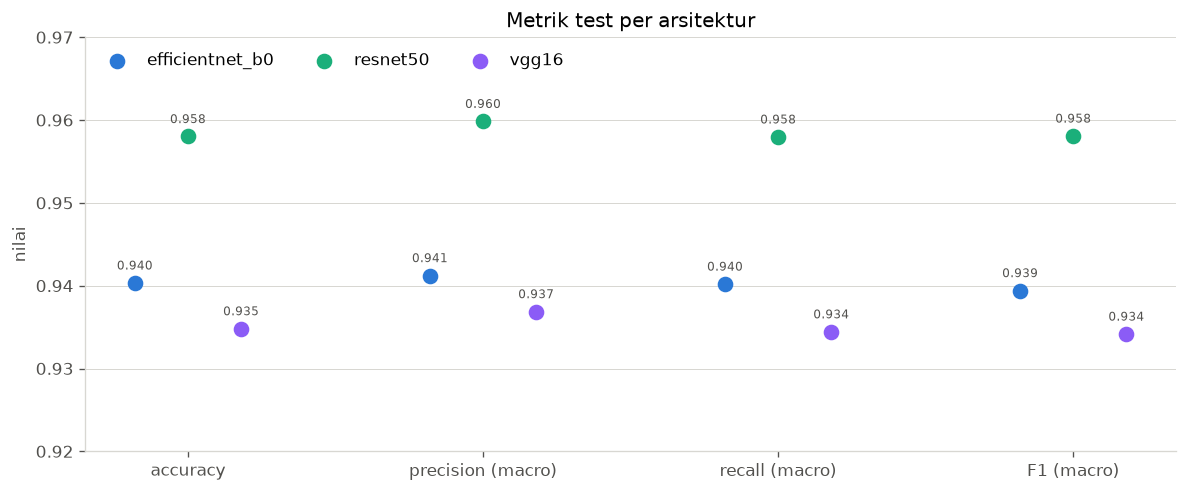

In [3]:
perf = pd.DataFrame([{
    "model": n,
    "accuracy": runs[n]["metrics"]["accuracy"],
    "precision_macro": runs[n]["metrics"]["precision_macro"],
    "recall_macro": runs[n]["metrics"]["recall_macro"],
    "f1_macro": runs[n]["metrics"]["f1_macro"],
    "top5_accuracy": runs[n]["metrics"]["top5_accuracy"],
    "val_f1_terbaik": runs[n]["metrics"]["best_val_macro_f1"],
    "n_salah": int((runs[n]["preds"] != runs[n]["trues"]).sum()),
} for n in MODELS]).sort_values("f1_macro", ascending=False)
BEST = perf.iloc[0]["model"]
print(perf.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nModel terbaik (macro-F1): {BEST}")
perf.to_csv(OUT_DIR / "tabel_performa.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
metrik = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
x = np.arange(len(metrik))
for k, n in enumerate(MODELS):
    nilai = perf.set_index("model").loc[n, metrik].to_numpy(dtype=float)
    ax.scatter(x + (k - 1) * 0.18, nilai, color=WARNA[n], s=70, zorder=3, label=n)
    for xi, v in zip(x + (k - 1) * 0.18, nilai):
        ax.annotate(f"{v:.3f}", xy=(xi, v), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=7, color=C_TEXT)
ax.set_xticks(x)
ax.set_xticklabels(["accuracy", "precision (macro)", "recall (macro)", "F1 (macro)"])
ax.set(ylim=(0.92, 0.97), ylabel="nilai", title="Metrik test per arsitektur")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()
simpan(fig, "metrik_test")
plt.show()

### 3.1 Selang Kepercayaan & Uji Signifikansi

Test set 905 citra, jadi selisih kecil bisa terjadi karena kebetulan. Bootstrap 95% CI dihitung per model;
uji McNemar membandingkan prediksi dua model pada citra yang sama.

          model  accuracy          acc_ci  f1_macro  f1_lo  f1_hi
       resnet50    0.9580 0.9447 – 0.9702    0.9581 0.9435 0.9702
efficientnet_b0    0.9403 0.9249 – 0.9558    0.9394 0.9231 0.9538
          vgg16    0.9348 0.9182 – 0.9503    0.9342 0.9166 0.9488


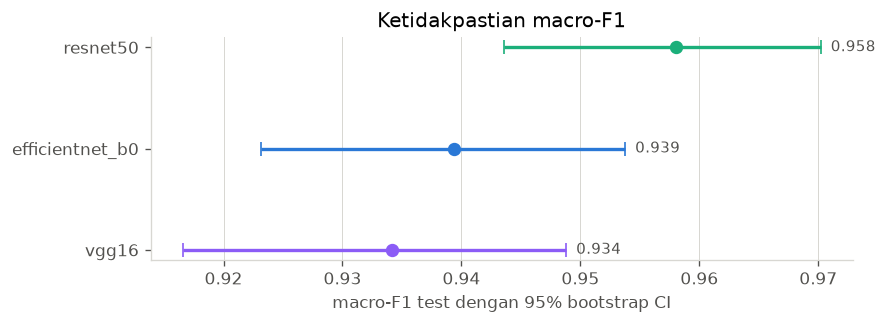

In [4]:
B = 2000
rng = np.random.default_rng(dp.SEED)
ci = []
for n in MODELS:
    t, p = runs[n]["trues"], runs[n]["preds"]
    acc_b, f1_b = [], []
    for _ in range(B):
        ii = rng.integers(0, len(t), len(t))
        acc_b.append((t[ii] == p[ii]).mean())
        f1_b.append(precision_recall_fscore_support(t[ii], p[ii], average="macro",
                                                    labels=range(len(CLASSES)), zero_division=0)[2])
    ci.append({"model": n, "accuracy": runs[n]["metrics"]["accuracy"],
               "acc_ci": f"{np.percentile(acc_b, 2.5):.4f} – {np.percentile(acc_b, 97.5):.4f}",
               "f1_macro": runs[n]["metrics"]["f1_macro"],
               "f1_lo": np.percentile(f1_b, 2.5), "f1_hi": np.percentile(f1_b, 97.5)})
ci = pd.DataFrame(ci).sort_values("f1_macro", ascending=False)
print(ci.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
ci.to_csv(OUT_DIR / "bootstrap_ci.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 2.8))
for k, r in enumerate(ci.iloc[::-1].itertuples()):
    ax.errorbar(r.f1_macro, k, xerr=[[r.f1_macro - r.f1_lo], [r.f1_hi - r.f1_macro]],
                fmt="o", color=WARNA[r.model], capsize=4, lw=2, ms=7)
    ax.annotate(f"{r.f1_macro:.3f}", xy=(r.f1_hi, k), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=C_TEXT)
ax.set_yticks(range(len(ci)))
ax.set_yticklabels(ci["model"].iloc[::-1])
ax.set(xlabel="macro-F1 test dengan 95% bootstrap CI", title="Ketidakpastian macro-F1")
ax.grid(axis="y", visible=False)
plt.tight_layout()
simpan(fig, "f1_ci")
plt.show()

In [5]:
uji = []
for a, b in itertools.combinations(MODELS, 2):
    if not (SAMA_TEST[a] and SAMA_TEST[b]):
        uji.append({"pasangan": f"{a} vs {b}", "a_benar_b_salah": "-", "a_salah_b_benar": "-",
                    "p_value": np.nan, "kesimpulan": "tidak diuji (test set berbeda)"})
        continue
    ba = runs[a]["preds"] == runs[a]["trues"]
    bb = runs[b]["preds"] == runs[b]["trues"]
    n01, n10 = int((ba & ~bb).sum()), int((~ba & bb).sum())
    p = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
    uji.append({"pasangan": f"{a} vs {b}", "a_benar_b_salah": n01, "a_salah_b_benar": n10,
                "p_value": p, "kesimpulan": "berbeda signifikan" if p < 0.05 else "tidak signifikan"})
uji = pd.DataFrame(uji)
print(uji.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
uji.to_csv(OUT_DIR / "uji_mcnemar.csv", index=False)

                   pasangan a_benar_b_salah a_salah_b_benar  p_value                     kesimpulan
efficientnet_b0 vs resnet50              16              32   0.0293             berbeda signifikan
   efficientnet_b0 vs vgg16               -               -      NaN tidak diuji (test set berbeda)
          resnet50 vs vgg16               -               -      NaN tidak diuji (test set berbeda)


## 4. Kurva Belajar

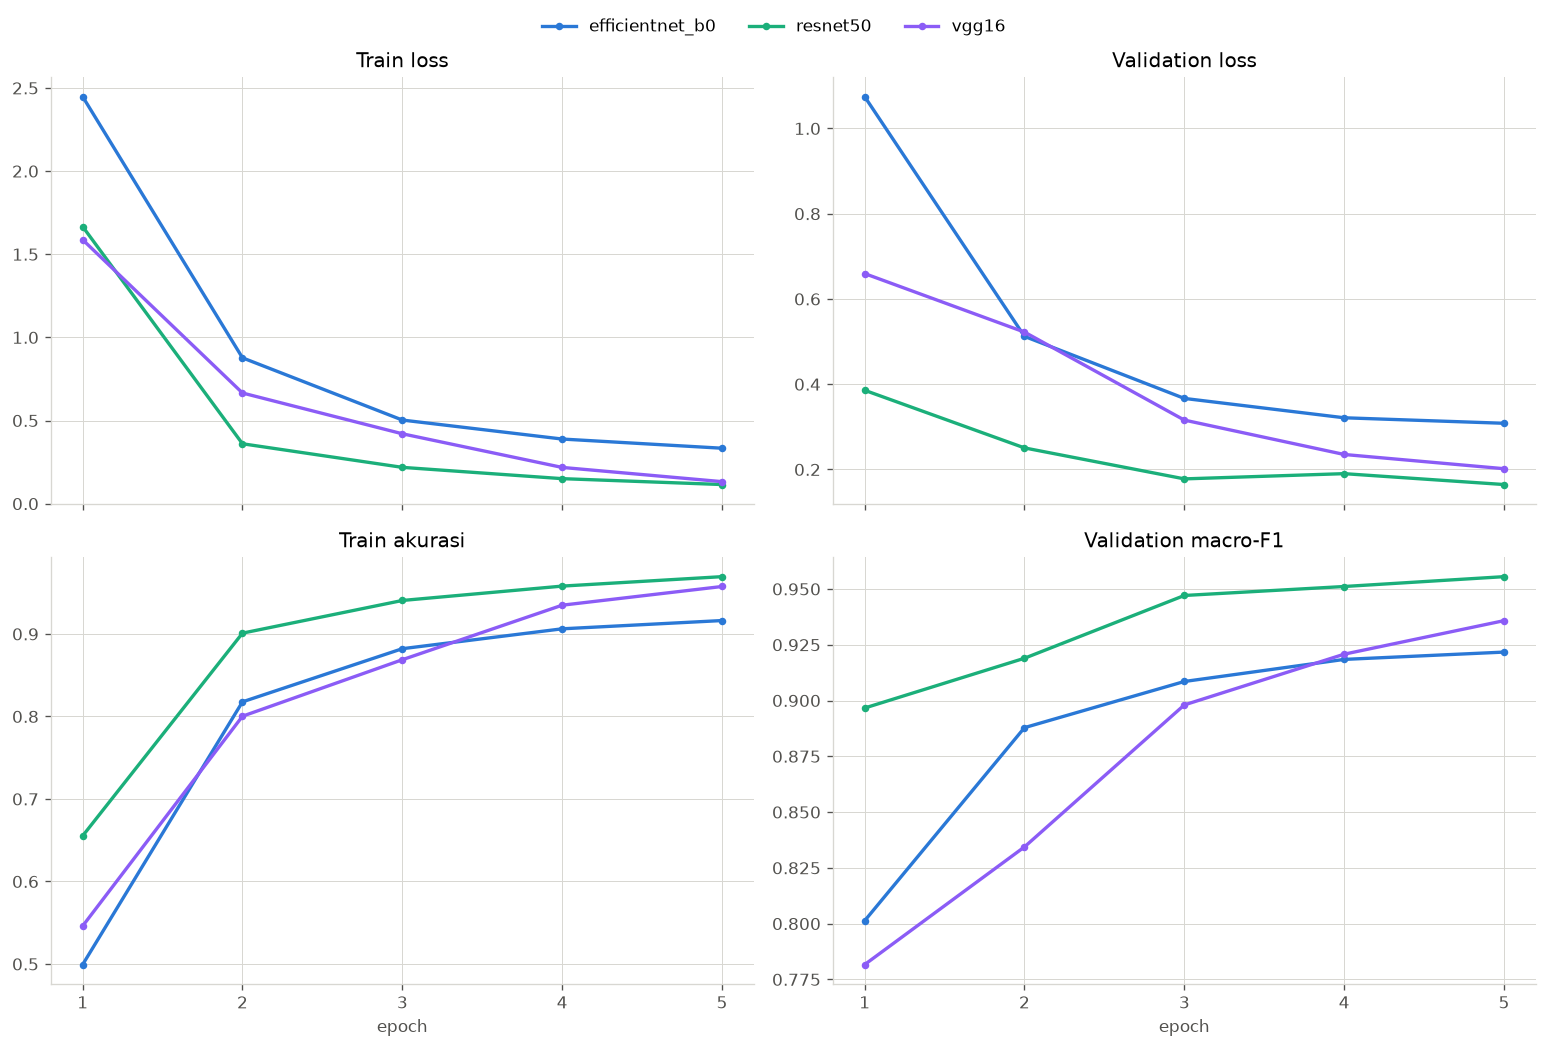

          model  val_f1_epoch1  val_f1_terbaik epoch_terbaik  gap_train_val_acc konvergen
efficientnet_b0         0.8013          0.9217           5/5            -0.0064     belum
       resnet50         0.8966          0.9555           5/5             0.0137     belum
          vgg16         0.7816          0.9358           5/5             0.0217     belum

gap_train_val_acc > 0.10 = overfitting.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
panel = [("train_loss", "Train loss"), ("val_loss", "Validation loss"),
         ("train_acc", "Train akurasi"), ("val_macro_f1", "Validation macro-F1")]
for ax, (kol, judul) in zip(axes.ravel(), panel):
    for n in MODELS:
        h = pd.DataFrame(runs[n]["history"])
        ax.plot(h["epoch"], h[kol], color=WARNA[n], lw=2, marker="o", ms=3.5, label=n)
    ax.set(title=judul)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes[1]:
    ax.set_xlabel("epoch")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
simpan(fig, "kurva_belajar")
plt.show()

konv = []
for n in MODELS:
    h = pd.DataFrame(runs[n]["history"])
    m = runs[n]["metrics"]
    hb = h.loc[h["epoch"] == m["best_epoch"]].iloc[0]
    konv.append({"model": n, "val_f1_epoch1": h["val_macro_f1"].iloc[0],
                 "val_f1_terbaik": m["best_val_macro_f1"],
                 "epoch_terbaik": f"{m['best_epoch']}/{m['epochs_run']}",
                 "gap_train_val_acc": hb["train_acc"] - hb["val_acc"],
                 "konvergen": "belum" if m["best_epoch"] == m["epochs_run"] else "ya"})
konv = pd.DataFrame(konv)
print(konv.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\ngap_train_val_acc > 0.10 = overfitting.")

## 5. Kompleksitas & Efisiensi

Jumlah parameter dan ukuran dihitung dari arsitektur. Latensi diukur ulang untuk ketiga model di
perangkat ini (bobot tidak memengaruhi latensi). Waktu training diambil dari `metrics.json` masing-masing
dan **tidak setara** karena berasal dari laptop berbeda.

In [7]:
import gc
import torch

def bersihkan():
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

lat = {n: {"b32": np.inf, "b1": np.inf} for n in MODELS}
info = {}
for _ in range(2):
    for n in MODELS:
        mdl = tr.build_model(n, num_classes=len(CLASSES), pretrained=False)
        info[n] = tr.count_parameters(mdl)
        lat[n]["b32"] = min(lat[n]["b32"], tr.measure_inference(mdl, DEVICE, batch_size=32, n=30)["latency_ms_per_image"])
        lat[n]["b1"] = min(lat[n]["b1"], tr.measure_inference(mdl, DEVICE, batch_size=1, n=50)["latency_ms_per_batch"])
        del mdl
        bersihkan()

eff = pd.DataFrame([{
    "model": n, "params_M": info[n]["total_params"] / 1e6, "ukuran_MB": info[n]["size_mb"],
    "ms_per_citra_b32": lat[n]["b32"], "ms_satu_citra_b1": lat[n]["b1"],
    "citra_per_detik": 1000 / lat[n]["b32"],
    "train_menit*": runs[n]["metrics"]["total_train_time_s"] / 60, "f1_macro": runs[n]["metrics"]["f1_macro"],
} for n in MODELS])
print(eff.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nLatensi diukur di {DEVICE}: median per pengukuran, terbaik dari 2 putaran.")
print("* waktu training dari laptop masing-masing, tidak bisa dibandingkan langsung.")
eff.to_csv(OUT_DIR / "tabel_efisiensi.csv", index=False)

          model  params_M  ukuran_MB  ms_per_citra_b32  ms_satu_citra_b1  citra_per_detik  train_menit*  f1_macro
efficientnet_b0     4.047     16.189             3.290             9.809          303.946        26.989     0.939
       resnet50    23.572     94.286             7.735            16.065          129.276         5.823     0.958
          vgg16   134.388    537.550            12.923            19.816           77.383        17.260     0.934

Latensi diukur di mps: median per pengukuran, terbaik dari 2 putaran.
* waktu training dari laptop masing-masing, tidak bisa dibandingkan langsung.


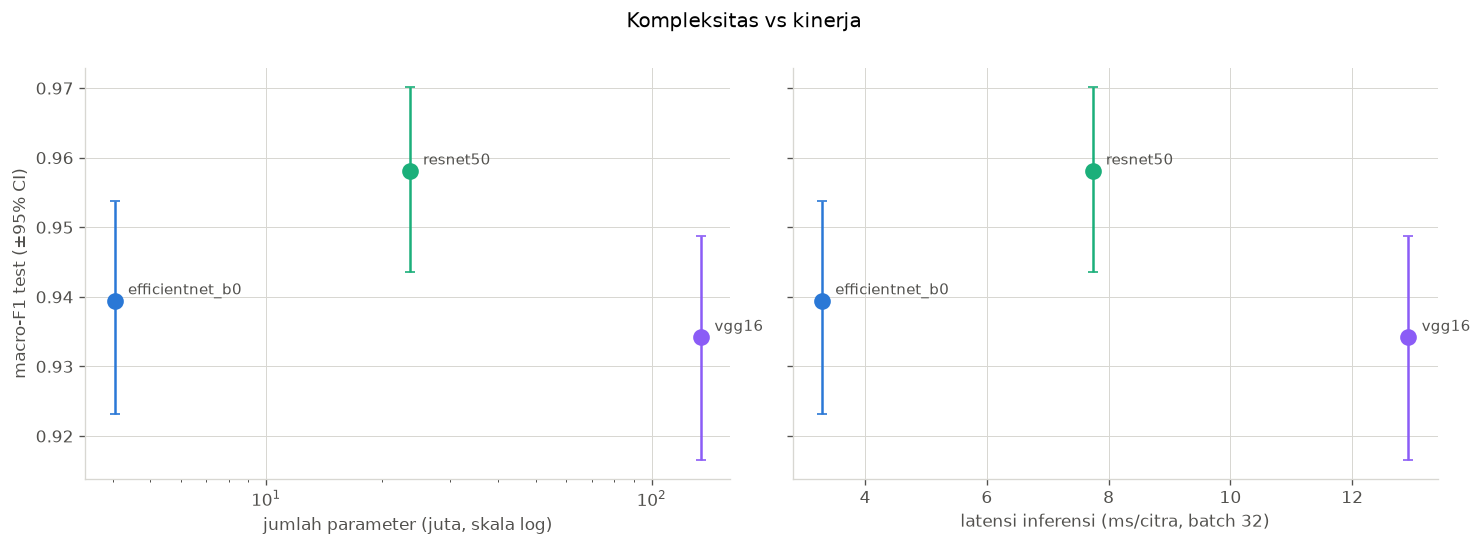

In [8]:
ci_i = ci.set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharey=True)
for ax, (kol, label, log) in zip(axes, [("params_M", "jumlah parameter (juta, skala log)", True),
                                        ("ms_per_citra_b32", "latensi inferensi (ms/citra, batch 32)", False)]):
    for r in eff.itertuples():
        lo, hi = ci_i.loc[r.model, "f1_lo"], ci_i.loc[r.model, "f1_hi"]
        x = getattr(r, kol)
        ax.errorbar(x, r.f1_macro, yerr=[[r.f1_macro - lo], [hi - r.f1_macro]], fmt="o",
                    color=WARNA[r.model], ms=9, capsize=3, lw=1.5)
        ax.annotate(r.model, xy=(x, r.f1_macro), xytext=(8, 4), textcoords="offset points",
                    fontsize=9, color=C_TEXT)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(label)
axes[0].set_ylabel("macro-F1 test (±95% CI)")
fig.suptitle("Kompleksitas vs kinerja", y=1.0)
plt.tight_layout()
simpan(fig, "kompleksitas_vs_kinerja")
plt.show()

## 6. Kinerja per Kelas

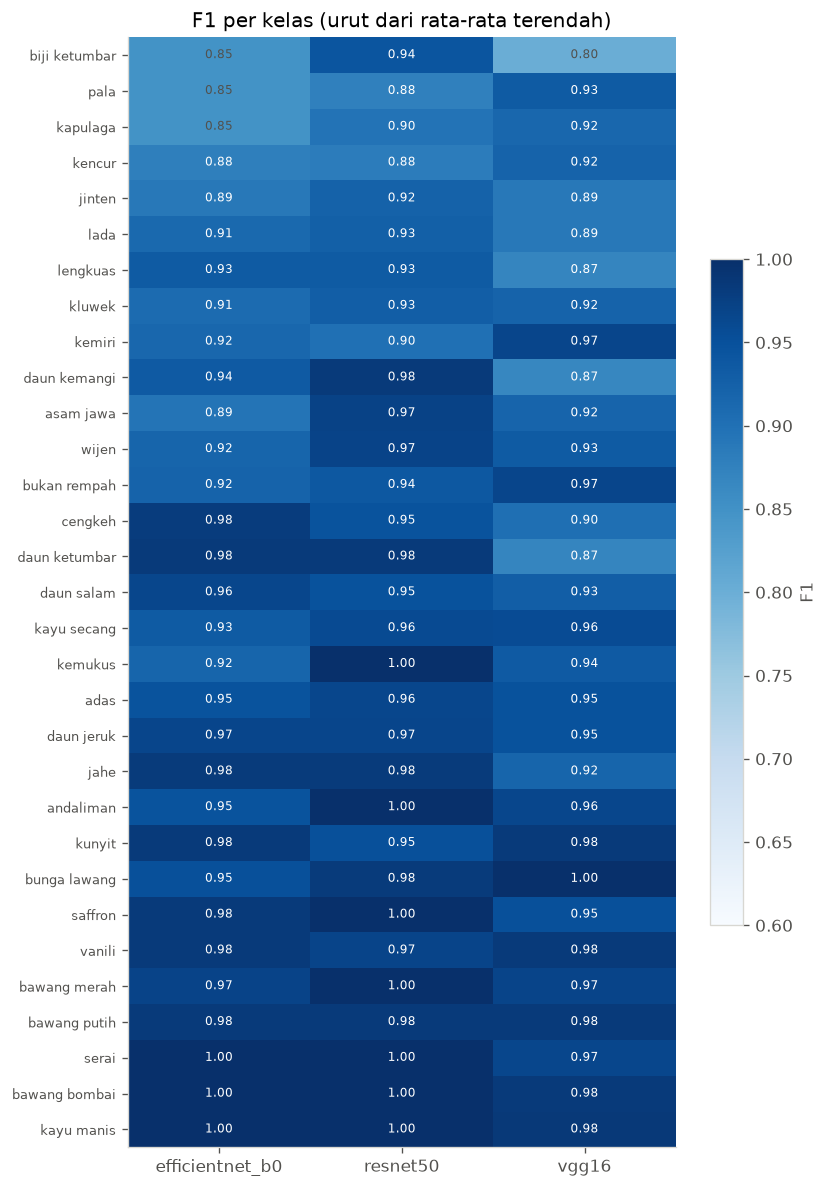

5 kelas tersulit (rata-rata):
               efficientnet_b0  resnet50  vgg16  rata2  rentang
biji ketumbar            0.847     0.943  0.800  0.864    0.143
pala                     0.847     0.875  0.933  0.885    0.086
kapulaga                 0.847     0.897  0.915  0.886    0.068
kencur                   0.877     0.881  0.921  0.893    0.043
jinten                   0.889     0.923  0.889  0.900    0.034

5 kelas dengan perbedaan antar model terbesar:
               efficientnet_b0  resnet50  vgg16  rata2  rentang
biji ketumbar            0.847     0.943  0.800  0.864    0.143
daun kemangi             0.935     0.984  0.866  0.928    0.118
daun ketumbar            0.983     0.983  0.868  0.945    0.115
pala                     0.847     0.875  0.933  0.885    0.086
kemukus                  0.918     1.000  0.935  0.951    0.082

Tiap kelas ~29 citra test: selisih 1 citra ≈ 0.03 F1.


In [9]:
f1_kelas = pd.DataFrame({n: runs[n]["per_class"]["f1"] for n in MODELS}, index=CLASSES)
f1_kelas["rata2"] = f1_kelas[MODELS].mean(axis=1)
f1_kelas = f1_kelas.sort_values("rata2")
f1_kelas.to_csv(OUT_DIR / "f1_per_kelas.csv")

fig, ax = plt.subplots(figsize=(7, 10))
data = f1_kelas[MODELS].to_numpy()
im = ax.imshow(data, cmap="Blues", vmin=0.6, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(MODELS)))
ax.set_xticklabels(MODELS)
ax.set_yticks(range(len(f1_kelas)))
ax.set_yticklabels(f1_kelas.index, fontsize=8)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if data[i, j] > 0.85 else C_TEXT)
ax.grid(visible=False)
ax.set_title("F1 per kelas (urut dari rata-rata terendah)")
fig.colorbar(im, ax=ax, shrink=0.6).set_label("F1", color=C_TEXT)
plt.tight_layout()
simpan(fig, "f1_per_kelas")
plt.show()

f1_kelas["rentang"] = f1_kelas[MODELS].max(axis=1) - f1_kelas[MODELS].min(axis=1)
print("5 kelas tersulit (rata-rata):")
print(f1_kelas.head(5).round(3).to_string())
print("\n5 kelas dengan perbedaan antar model terbesar:")
print(f1_kelas.sort_values("rentang", ascending=False).head(5).round(3).to_string())
print(f"\nTiap kelas ~29 citra test: selisih 1 citra ≈ 0.03 F1.")

In [10]:
kumpulan = {}
for n in MODELS:
    cm = runs[n]["cm"]
    for i, j in zip(*np.nonzero(cm)):
        if i != j:
            kumpulan.setdefault((CLASSES[i], CLASSES[j]), {})[n] = int(cm[i, j])

tertukar = pd.DataFrame([
    {"sebenarnya": a, "diprediksi": b, **{n: v.get(n, 0) for n in MODELS},
     "total": sum(v.values()), "jumlah_model": len(v)}
    for (a, b), v in kumpulan.items()
]).sort_values(["total", "jumlah_model"], ascending=False)
print("Pasangan kelas paling sering tertukar (gabungan 3 model):")
print(tertukar.head(12).to_string(index=False))

Pasangan kelas paling sering tertukar (gabungan 3 model):
   sebenarnya    diprediksi  efficientnet_b0  resnet50  vgg16  total  jumlah_model
biji ketumbar          lada                3         3      4     10             3
         adas        jinten                3         2      2      7             3
     kapulaga biji ketumbar                3         0      4      7             2
daun ketumbar  daun kemangi                0         0      6      6             1
       kencur      lengkuas                2         2      1      5             3
         pala  bukan rempah                3         2      0      5             2
   daun salam    daun jeruk                1         2      1      4             3
       kemiri      kapulaga                2         1      1      4             3
    andaliman       kemukus                3         0      1      4             2
       kluwek          pala                2         2      0      4             2
        wijen biji ketumbar  

## 7. Confusion Matrix

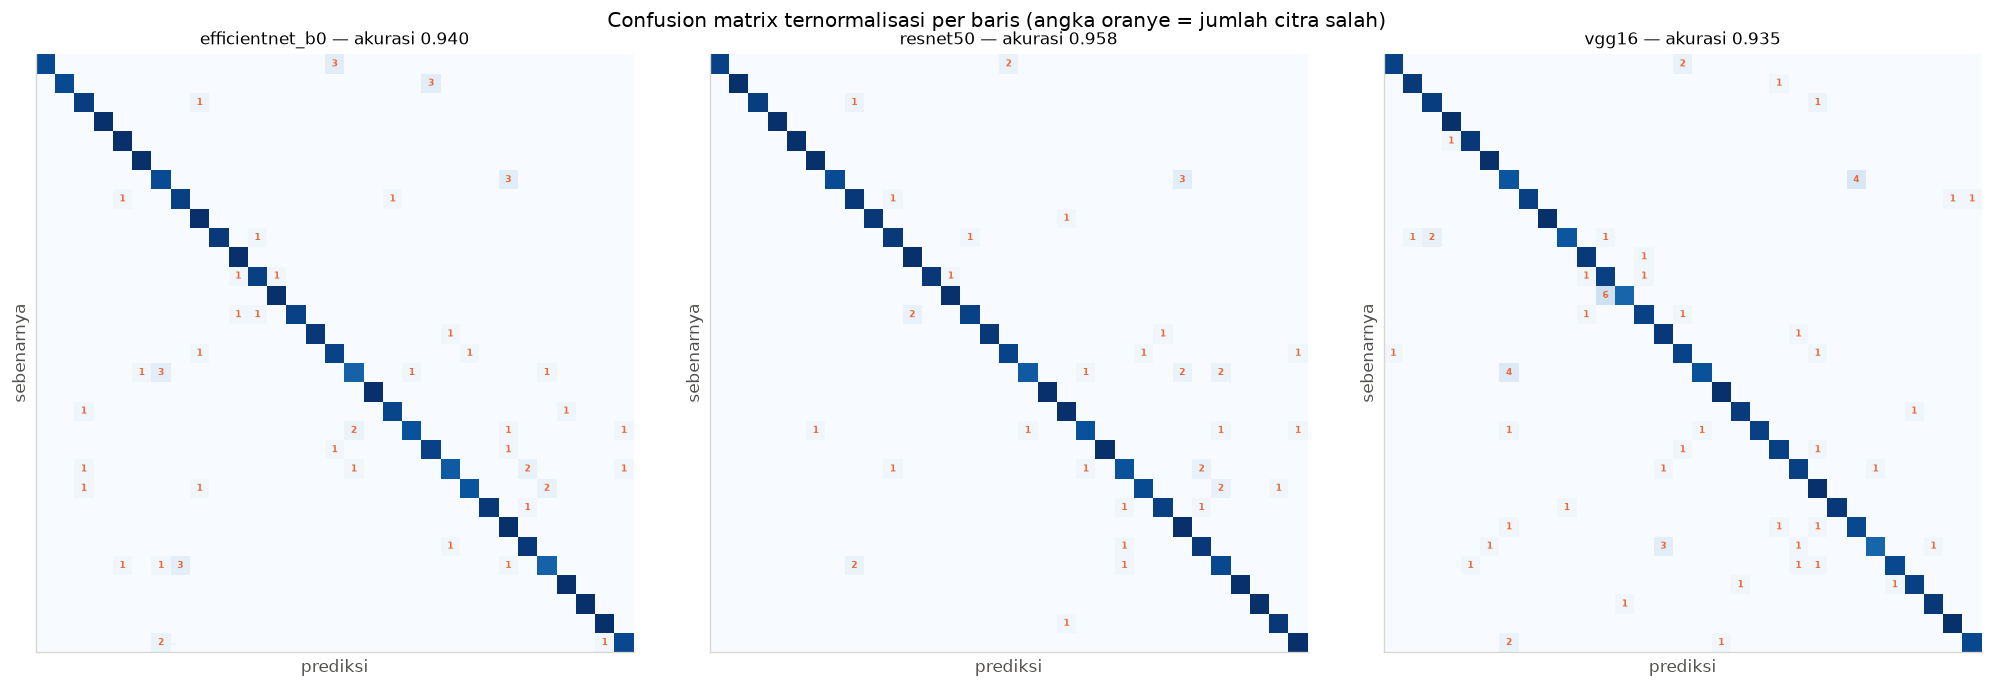

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, n in zip(axes, MODELS):
    cm = runs[n]["cm"]
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i, j in zip(*np.nonzero(cm)):
        if i != j:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5.5, color=C_SALAH, fontweight="bold")
    ax.set_title(f"{n} — akurasi {runs[n]['metrics']['accuracy']:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set(xlabel="prediksi", ylabel="sebenarnya")
    ax.grid(visible=False)
fig.suptitle("Confusion matrix ternormalisasi per baris (angka oranye = jumlah citra salah)")
plt.tight_layout()
simpan(fig, "confusion_matrix_3_model")
plt.show()

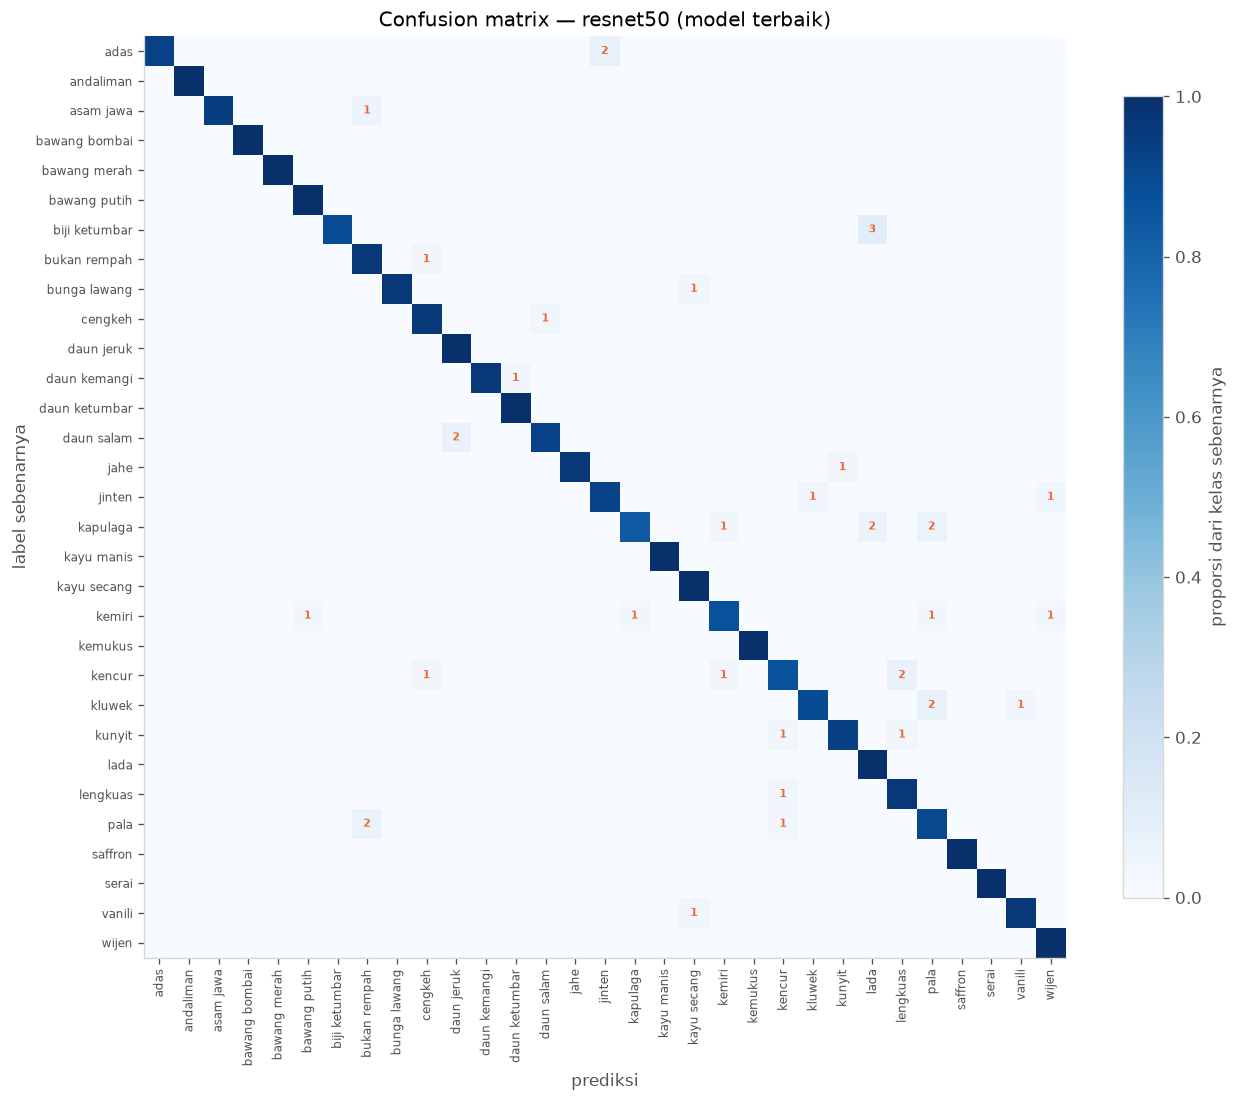

In [12]:
cm = runs[BEST]["cm"]
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticklabels(CLASSES, fontsize=7)
for i, j in zip(*np.nonzero(cm)):
    if i != j:
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5, color=C_SALAH, fontweight="bold")
ax.set(xlabel="prediksi", ylabel="label sebenarnya", title=f"Confusion matrix — {BEST} (model terbaik)")
ax.grid(visible=False)
fig.colorbar(im, ax=ax, shrink=0.8).set_label("proporsi dari kelas sebenarnya", color=C_TEXT)
plt.tight_layout()
simpan(fig, f"confusion_matrix_{BEST}")
plt.show()

## 8. Prediksi Model Terbaik

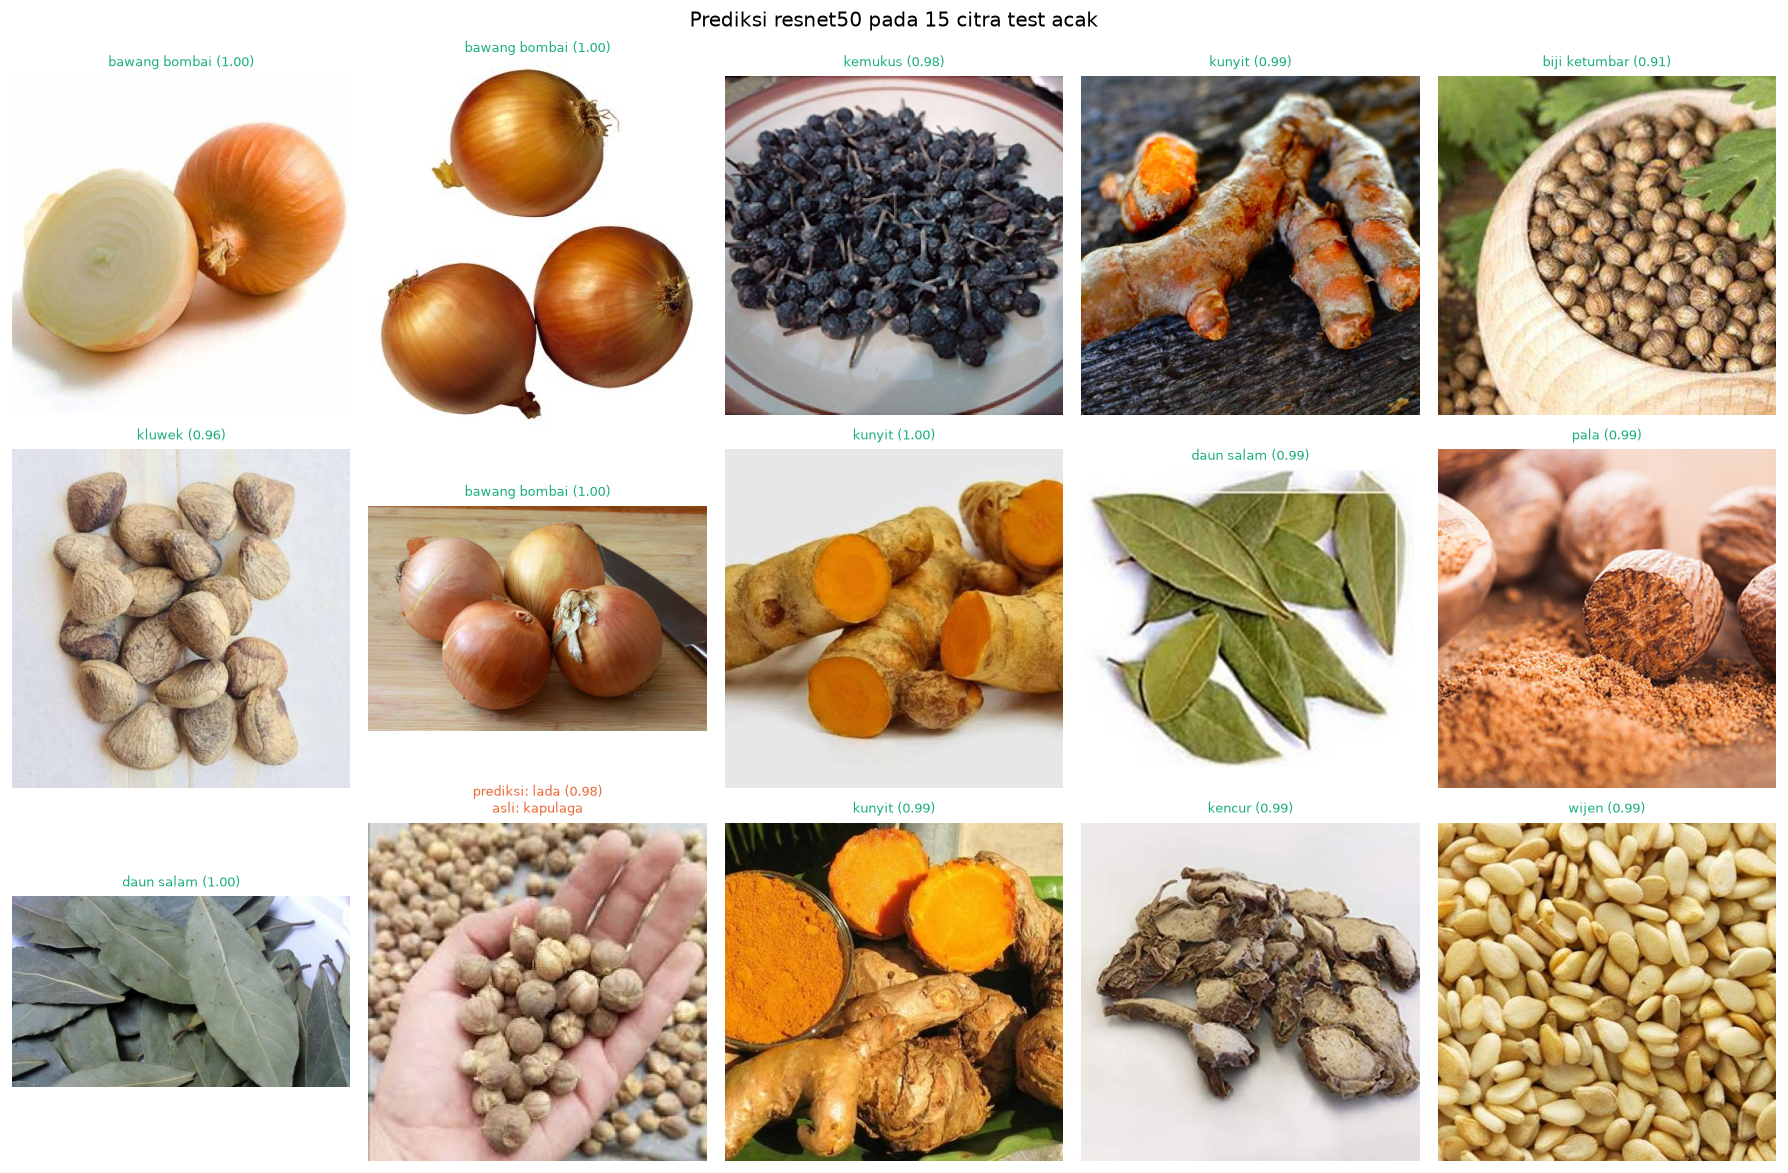

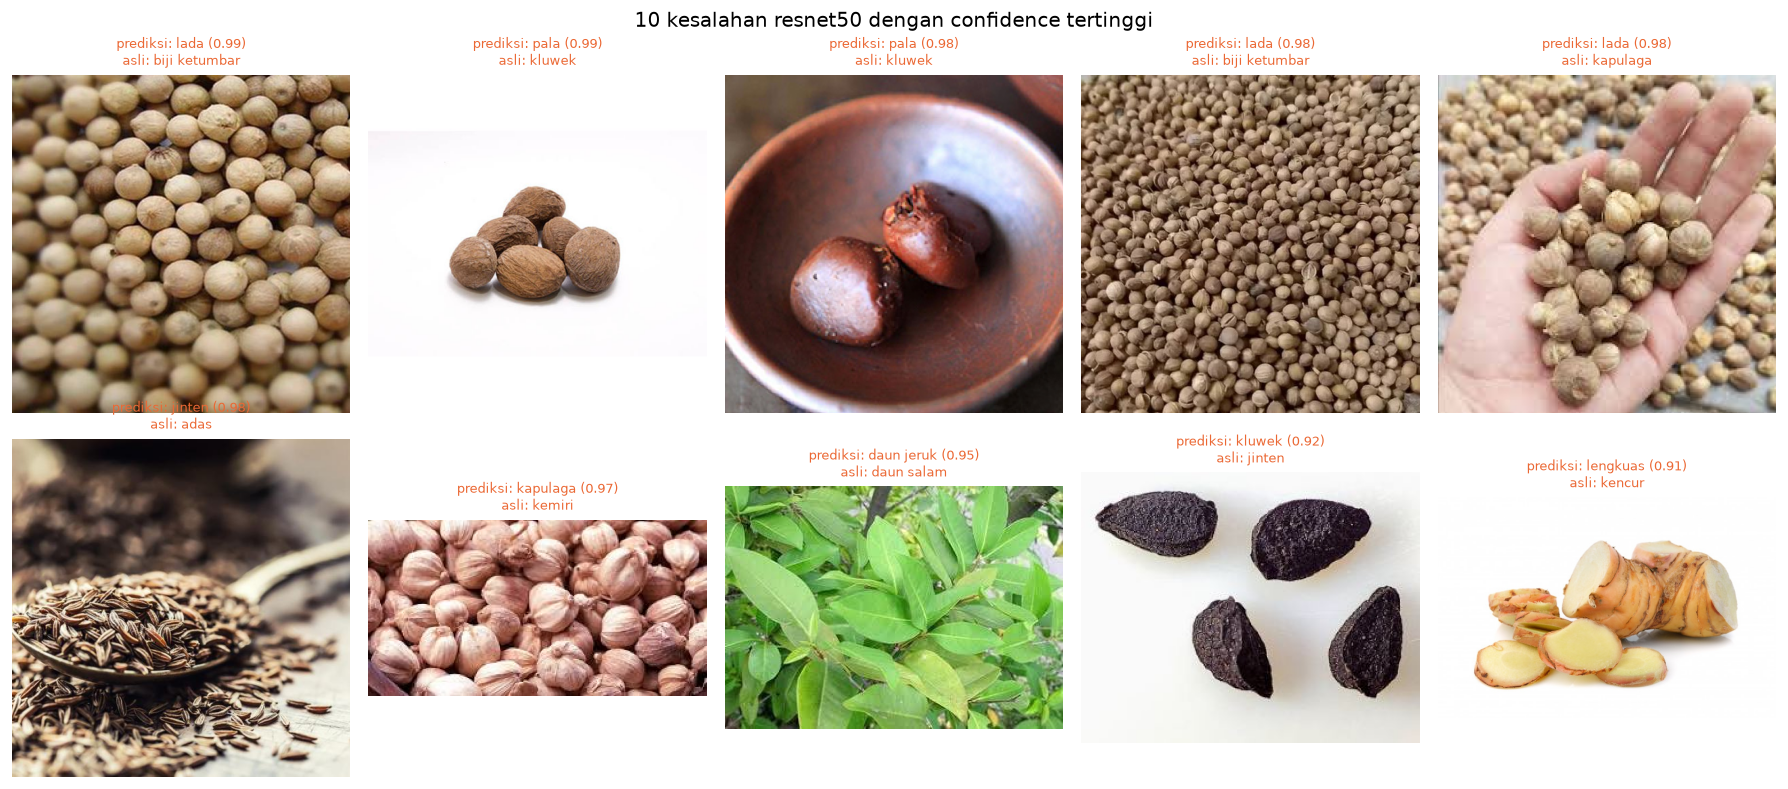

In [13]:
ds = dp.build_datasets()
paths = [p for p, _ in ds["test"].samples]
trues_b, preds_b, probs_b = runs[BEST]["trues"], runs[BEST]["preds"], runs[BEST]["probs"]
assert np.array_equal([y for _, y in ds["test"].samples], trues_b), "test set lokal berbeda dengan hasil model"
conf_b = probs_b[np.arange(len(preds_b)), preds_b]

def grid_citra(indeks, judul, nama_file, kolom=5):
    brs = int(np.ceil(len(indeks) / kolom))
    fig, axes = plt.subplots(brs, kolom, figsize=(3 * kolom, 3.35 * brs), squeeze=False)
    for ax, i in zip(axes.ravel(), indeks):
        ax.imshow(Image.open(paths[i]).convert("RGB"))
        ok = preds_b[i] == trues_b[i]
        teks = (f"{CLASSES[preds_b[i]]} ({conf_b[i]:.2f})" if ok else
                f"prediksi: {CLASSES[preds_b[i]]} ({conf_b[i]:.2f})\nasli: {CLASSES[trues_b[i]]}")
        ax.set_title(teks, fontsize=8, color=C_OK if ok else C_SALAH)
        ax.axis("off")
    for ax in axes.ravel()[len(indeks):]:
        ax.axis("off")
    fig.suptitle(judul)
    plt.tight_layout()
    simpan(fig, nama_file)
    plt.show()

acak = np.random.default_rng(dp.SEED).choice(len(paths), 15, replace=False)
grid_citra(acak, f"Prediksi {BEST} pada 15 citra test acak", "prediksi_acak")

salah = np.where(preds_b != trues_b)[0]
grid_citra(salah[np.argsort(-conf_b[salah])][:10], f"10 kesalahan {BEST} dengan confidence tertinggi",
           "kesalahan_terbesar")

Citra yang salah di semua model (efficientnet_b0, resnet50): 22


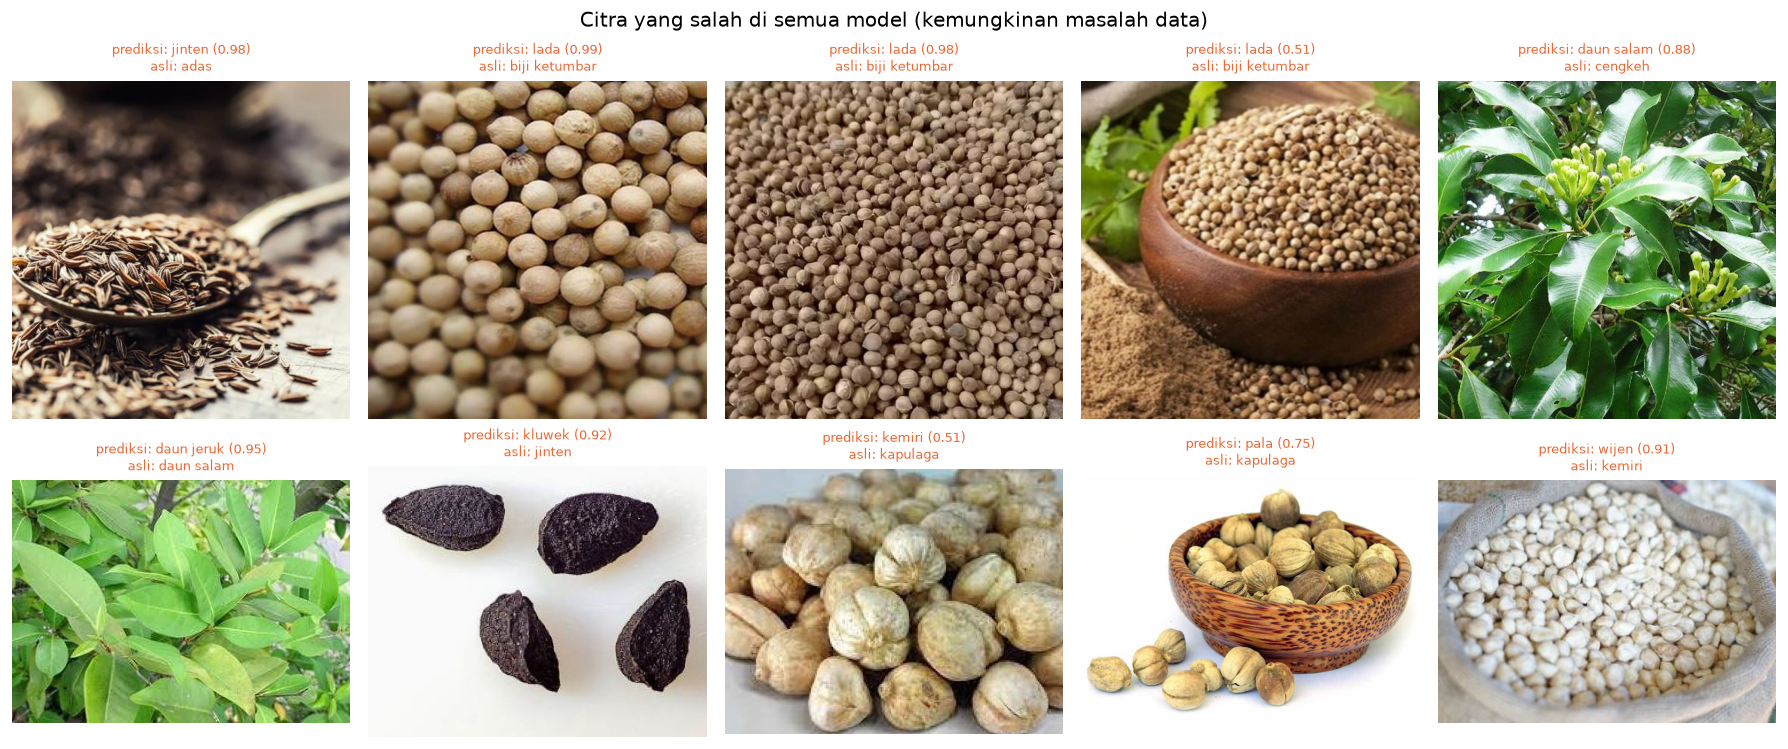

In [14]:
benar = np.stack([runs[n]["preds"] == runs[n]["trues"] for n in MODELS if SAMA_TEST[n]])
salah_semua = np.where(~benar.any(axis=0))[0]
nama = [n for n in MODELS if SAMA_TEST[n]]
print(f"Citra yang salah di semua model ({', '.join(nama)}): {len(salah_semua)}")
if len(salah_semua):
    grid_citra(salah_semua[:10], "Citra yang salah di semua model (kemungkinan masalah data)", "salah_semua_model")

## 9. Ringkasan

In [15]:
p = perf.set_index("model")
e = eff.set_index("model")
print(f"- Terbaik: {BEST} — akurasi {p.loc[BEST, 'accuracy']:.2%}, macro-F1 {p.loc[BEST, 'f1_macro']:.4f}")
for n in MODELS:
    print(f"  {n:16s} akurasi {p.loc[n, 'accuracy']:.4f} | F1 {p.loc[n, 'f1_macro']:.4f} | "
          f"{e.loc[n, 'params_M']:6.1f} M param | {e.loc[n, 'ms_per_citra_b32']:.2f} ms/citra")
sig = uji.dropna(subset=["p_value"])
for r in sig.itertuples():
    print(f"- McNemar {r.pasangan}: p = {r.p_value:.4f} ({r.kesimpulan})")
print(f"- Belum konvergen dalam 5 epoch: {', '.join(konv.loc[konv['konvergen'] == 'belum', 'model'])}")
print(f"- Kelas tersulit lintas model: {', '.join(f1_kelas.index[:3])}")
print(f"- Grafik & tabel: {OUT_DIR}")

- Terbaik: resnet50 — akurasi 95.80%, macro-F1 0.9581
  efficientnet_b0  akurasi 0.9403 | F1 0.9394 |    4.0 M param | 3.29 ms/citra
  resnet50         akurasi 0.9580 | F1 0.9581 |   23.6 M param | 7.74 ms/citra
  vgg16            akurasi 0.9348 | F1 0.9342 |  134.4 M param | 12.92 ms/citra
- McNemar efficientnet_b0 vs resnet50: p = 0.0293 (berbeda signifikan)
- Belum konvergen dalam 5 epoch: efficientnet_b0, resnet50, vgg16
- Kelas tersulit lintas model: biji ketumbar, pala, kapulaga
- Grafik & tabel: /Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/results/comparison


## 10. Kesimpulan

- **ResNet50 terbaik**: akurasi 95.8%, macro-F1 0.958. Keunggulannya atas EfficientNet-B0 signifikan
  (McNemar p = 0.029). Bobot awal `IMAGENET1K_V2` yang lebih modern ikut berkontribusi.
- **EfficientNet-B0 paling efisien**: 6× lebih sedikit parameter dan ±2× lebih cepat dari ResNet50, dengan
  akurasi 1.8 poin di bawahnya.
- **VGG16 paling boros**: 134 M parameter dan inferensi paling lambat, tetapi akurasinya terendah (93.5%).
  Parameter terbanyak tidak menjamin kinerja terbaik pada dataset kecil (~136 citra train/kelas).
- **Ketiga model belum konvergen** dalam 5 epoch dan tidak overfitting (gap train-val < 0.03).
- **Kelas tersulit sama untuk semua model**: biji ketumbar, pala, kapulaga. Pasangan biji ketumbar→lada
  dan adas→jinten tertukar di ketiga model, jadi penyebabnya kemiripan visual, bukan arsitektur.
- **Keterbatasan**: split VGG16 berbeda tipis, dan waktu training berasal dari laptop berbeda.